# Bloque 1: #
Importa las librerías esenciales (pandas, pathlib, gc) y establece la estructura del sistema de archivos. Configura automáticamente las rutas del directorio de trabajo, la carpeta de entrada con los archivos CSV (matriculaaaas) y crea el directorio de salida (resultados_parquet) si aún no existe.

In [1]:
import gc
from pathlib import Path
import pandas as pd

# Definición de rutas automáticas en tu computador
BASE_DIR = Path.cwd()
CARPETA_CSV = BASE_DIR / "matriculaaaas"
CARPETA_SALIDA = BASE_DIR / "resultados_parquet"

# Confirmar existencia de directorios
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

print(f"Directorio de trabajo: {BASE_DIR}")
print(f"Buscando archivos CSV en: {CARPETA_CSV}")
print(f"Guardando resúmenes Parquet en: {CARPETA_SALIDA}")

Directorio de trabajo: /home/leandro/Desktop/Carreras
Buscando archivos CSV en: /home/leandro/Desktop/Carreras/matriculaaaas
Guardando resúmenes Parquet en: /home/leandro/Desktop/Carreras/resultados_parquet


# Bloque 2: #
Define la función procesar_anio, encargada del ETL individual. Carga el CSV anual, filtra registros de Universidades y nivel de Pregrado, detecta e imputa valores nulos o códigos especiales de ingreso (1900, 9995, etc.), audita la presencia de identificadores únicos (MRUN), evalúa inconsistencias en aranceles o duraciones y exporta el resultado consolidado por programa en formato Parquet comprimido.

In [2]:
def procesar_anio(
    ruta_csv, anio, carpeta_salida=CARPETA_SALIDA, encoding="utf-8"
):
  ruta_csv = Path(ruta_csv)
  salida = Path(carpeta_salida) / f"resumen_{anio}_provisional.parquet"

  if not ruta_csv.is_file():
    raise FileNotFoundError(f"No se encontró el CSV: {ruta_csv}")

  # 1. Cargar archivo preservando formatos originales
  datos = pd.read_csv(ruta_csv, sep=";", encoding=encoding, dtype="string")
  datos.columns = datos.columns.str.strip().str.lower()

  if datos.columns.duplicated().any():
    raise ValueError("Hay nombres de columnas duplicados en el CSV.")

  for columna in datos.columns:
    datos[columna] = datos[columna].str.strip().replace("", pd.NA)

  necesarias = [
      "cat_periodo",
      "codigo_unico",
      "mrun",
      "tipo_inst_1",
      "nivel_global",
      "anio_ing_carr_ori",
  ]
  faltantes = [c for c in necesarias if c not in datos.columns]
  if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {faltantes}")

  filas_originales = len(datos)

  # 2. Filtrar Universidades y Pregrado
  filtro = (
      datos["tipo_inst_1"].str.casefold().eq("universidades")
      & datos["nivel_global"].str.casefold().eq("pregrado")
  ).fillna(False)

  base = datos.loc[filtro].copy()
  del datos, filtro
  gc.collect()

  if base.empty:
    raise ValueError("No se encontraron registros de universidades y pregrado.")

  base["cat_periodo"] = anio
  claves = ["cat_periodo", "codigo_unico"]

  # 3. Auditoría de primer ingreso
  ingreso = pd.to_numeric(base["anio_ing_carr_ori"], errors="coerce")
  es_nuevo = ingreso.eq(anio).fillna(False)
  por_revisar = (
      ingreso.isna()
      | ingreso.isin([1900, 9995, 9998, 9999])
      | ingreso.gt(anio)
      | ingreso.le(0)
      | ingreso.mod(1).ne(0)
  ).fillna(True)

  nuevos = base.loc[es_nuevo]

  # 4. Agrupaciones y conteos
  conteos = (
      nuevos.groupby(claves)
      .agg(
          registros_primer_ingreso=("codigo_unico", "size"),
          ingresantes_identificados=("mrun", "nunique"),
          registros_sin_mrun=("mrun", lambda s: s.isna().sum()),
      )
      .reset_index()
  )

  pendientes = (
      base.loc[por_revisar]
      .groupby(claves)
      .size()
      .rename("registros_ingreso_por_revisar")
      .reset_index()
  )

  resumen = base[claves].drop_duplicates().merge(
      conteos, on=claves, how="left", validate="one_to_one"
  ).merge(pendientes, on=claves, how="left", validate="one_to_one")

  columnas_conteo = [
      "registros_primer_ingreso",
      "ingresantes_identificados",
      "registros_sin_mrun",
      "registros_ingreso_por_revisar",
  ]
  resumen[columnas_conteo] = resumen[columnas_conteo].fillna(0).astype("int64")

  resumen["conteo_requiere_revision"] = (
      resumen["registros_sin_mrun"].gt(0)
      | resumen["registros_ingreso_por_revisar"].gt(0)
  )

  resumen["estado_conteo"] = "Sin incidencias detectadas"
  resumen.loc[
      resumen["registros_primer_ingreso"].eq(0), "estado_conteo"
  ] = "Cero observado: verificar admisión"
  resumen.loc[
      resumen["conteo_requiere_revision"], "estado_conteo"
  ] = "Pendiente de revisión"

  resumen["nuevos_ingresados_provisional"] = (
      resumen["ingresantes_identificados"]
      .astype("Int64")
      .where(resumen["estado_conteo"].eq("Sin incidencias detectadas"))
  )

  # 5. Atributos y detección de conflictos
  atributos = [
      "cod_inst",
      "nomb_inst",
      "cod_sede",
      "nomb_sede",
      "cod_carrera",
      "nomb_carrera",
      "version",
      "tipo_inst_1",
      "tipo_inst_2",
      "tipo_inst_3",
      "nivel_global",
      "nivel_carrera_1",
      "nivel_carrera_2",
      "tipo_plan_carr",
      "jornada",
      "modalidad",
      "vigencia_carrera",
      "region_sede",
      "provincia_sede",
      "comuna_sede",
      "area_conocimiento",
      "area_carrera_generica",
      "dur_total_carr",
      "valor_arancel",
      "valor_matricula",
      "formato_valores",
      "acreditada_carr",
      "acreditada_inst",
      "acre_inst_anio",
  ]

  ausentes = [c for c in atributos if c not in base.columns]
  for columna in ausentes:
    base[columna] = pd.Series(pd.NA, index=base.index, dtype="string")

  grupos = base.groupby(claves)
  distintos = grupos[atributos].nunique(dropna=True)
  valores = grupos[atributos].first().mask(distintos.gt(1))
  marcas = distintos.gt(1).add_suffix("_conflicto")

  resumen = resumen.merge(
      valores.join(marcas).reset_index(),
      on=claves,
      how="left",
      validate="one_to_one",
  )

  # 6. Diagnóstico de campos numéricos
  columnas_numericas = [
      "valor_arancel",
      "valor_matricula",
      "dur_total_carr",
      "acre_inst_anio",
  ]
  for columna in columnas_numericas:
    texto = resumen[columna].astype("string")
    interpretable = texto.str.fullmatch(r"[+-]?\d+(?:\.0+)?", na=False)
    resumen[f"{columna}_numerico"] = pd.to_numeric(
        texto.where(interpretable), errors="coerce"
    ).astype("Float64")
    resumen[f"{columna}_faltante"] = texto.isna()
    resumen[f"{columna}_formato_por_revisar"] = texto.notna() & ~interpretable

  duracion = resumen["dur_total_carr_numerico"]
  resumen["duracion_por_revisar"] = (
      duracion.isna() | duracion.lt(4) | duracion.gt(16)
  ).fillna(True)
  resumen["archivo_origen"] = ruta_csv.name

  # Guardar archivo Parquet
  resumen.to_parquet(salida, index=False, compression="snappy")

  del grupos, nuevos, base
  gc.collect()

  return resumen, salida

# Bloque 3: #
Define la función exportar_diagnostico_ia, que recibe el DataFrame procesado y construye un informe estructurado en formato de texto plano (.txt). Muestra la distribución de programas según su estado de conteo, resumen global de ingresantes con y sin MRUN, banderas de anomalías financieras y una muestra del Top 10 de carreras que requieren auditoría manual.

In [3]:
def exportar_diagnostico_ia(resumen, anio):
  """Genera un reporte sintético en texto plano para copiar/analizar."""
  informe = []
  informe.append(f"=== INFORME DE DIAGNÓSTICO DE DATOS ({anio}) ===")

  # 1. Estado general de los conteos
  informe.append("\n--- 1. ESTADO DE CONTEOS DE PROGRAMAS ---")
  estados = resumen["estado_conteo"].value_counts()
  for estado, cant in estados.items():
    informe.append(f"- {estado}: {cant} programas")

  # 2. Métricas globales de admisión
  informe.append("\n--- 2. MÉTRICAS GLOBALES DE ADMISIÓN ---")
  informe.append(f"- Total de programas observados: {len(resumen):,}")
  informe.append(
      "- Ingresantes identificados totales:"
      f" {resumen['ingresantes_identificados'].sum():,}"
  )
  informe.append(
      "- Registros de primer ingreso sin MRUN:"
      f" {resumen['registros_sin_mrun'].sum():,}"
  )
  informe.append(
      "- Registros con ingreso por revisar:"
      f" {resumen['registros_ingreso_por_revisar'].sum():,}"
  )

  # 3. Detección de anomalías en montos y duraciones
  informe.append("\n--- 3. DETECCIÓN DE ANOMALÍAS DE DATO Y FORMATO ---")
  for col, desc in [
      ("valor_arancel_cero", "Aranceles informados en $0"),
      ("valor_arancel_negativo", "Aranceles con valores negativos"),
      ("duracion_por_revisar", "Duraciones fuera de rango (menos de 4 o más de 16 semestres)"),
      ("unidad_monetaria_no_informada", "Programas sin formato de valor informados"),
  ]:
    if col in resumen.columns:
      informe.append(f"- {desc}: {resumen[col].sum()} programas")

  # 4. Muestra de programas que requieren revisión
  pendientes = resumen[resumen["estado_conteo"] != "Sin incidencias detectadas"]
  if not pendientes.empty:
    informe.append(
        "\n--- 4. MUESTRA DE PROGRAMAS QUE REQUIEREN REVISIÓN (Top 10) ---"
    )
    cols_mostrar = [
        c
        for c in [
            "codigo_unico",
            "nomb_inst",
            "nomb_carrera",
            "estado_conteo",
            "registros_sin_mrun",
            "registros_ingreso_por_revisar",
        ]
        if c in resumen.columns
    ]
    informe.append(pendientes[cols_mostrar].head(10).to_string(index=False))

  texto_final = "\n".join(informe)
  print(texto_final)
  return texto_final

# Bloque 4: #
Escanea la carpeta de entrada buscando todos los archivos .csv, extrae el año correspondiente mediante expresiones regulares (re) y ejecuta secuencialmente la función de limpieza (procesar_anio) y la de informe (exportar_diagnostico_ia). Guarda los archivos .parquet y los reportes .txt individuales para cada año detectado.

In [7]:
import re
from pathlib import Path

# Carpeta para guardar los reportes de diagnóstico en texto plano
CARPETA_REPORTES = BASE_DIR / "reportes_diagnostico"
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)

# Buscar todos los archivos .csv en la carpeta matriculaaaas
archivos_csv = sorted(CARPETA_CSV.glob("*.csv"))

if not archivos_csv:
  print(f"⚠️ No se encontraron archivos .csv en {CARPETA_CSV}")
else:
  print(f"📁 Se encontraron {len(archivos_csv)} archivos CSV para procesar.\n")

# Bucle automático para procesar cada año
for archivo in archivos_csv:
  # Extraer el año real del dataset (el número de 4 dígitos antes de _PUBL)
  coincidencia = re.search(r"_(\d{4})_PUBL", archivo.name)

  if not coincidencia:
    # Alternativa si el archivo no tiene _PUBL: tomar la última secuencia de 4 dígitos
    todos_los_anios = re.findall(r"(?:19|20)\d{2}", archivo.name)
    if len(todos_los_anios) >= 2:
      anio = int(todos_los_anios[-1])  # El segundo año es el del dataset
    elif todos_los_anios:
      anio = int(todos_los_anios[0])
    else:
      print(
          "⚠️ No se pudo identificar el año en el archivo:"
          f" {archivo.name}. Se omite."
      )
      continue
  else:
    anio = int(coincidencia.group(1))

  print("=" * 60)
  print(f"🔄 PROCESANDO AÑO REVELADO: {anio} | Archivo: {archivo.name}")
  print("=" * 60)

  try:
    # 1. Procesar el CSV y guardar el Parquet
    df_resumen, ruta_parquet = procesar_anio(ruta_csv=archivo, anio=anio)

    # 2. Generar el informe en texto
    informe_texto = exportar_diagnostico_ia(df_resumen, anio)

    # 3. Guardar el informe de diagnóstico por separado (.txt)
    ruta_txt = CARPETA_REPORTES / f"diagnostico_{anio}.txt"
    ruta_txt.write_text(informe_texto, encoding="utf-8")

    print(f"\n✅ Año {anio} completado exitosamente.")
    print(f"   └─ Parquet: {ruta_parquet.name}")
    print(f"   └─ Reporte TXT: {ruta_txt.name}\n")

  except Exception as e:
    print(f"❌ Error al procesar el año {anio} ({archivo.name}): {e}\n")

print("=" * 60)
print("🎉 ¡Proceso finalizado! Todos los reportes individuales se guardaron en:")
print(f"   {CARPETA_REPORTES}")

📁 Se encontraron 19 archivos CSV para procesar.

🔄 PROCESANDO AÑO REVELADO: 2007 | Archivo: 20260810_Matrícula_Ed_Superior_2007_PUBL_MRUN.csv
=== INFORME DE DIAGNÓSTICO DE DATOS (2007) ===

--- 1. ESTADO DE CONTEOS DE PROGRAMAS ---
- Sin incidencias detectadas: 2706 programas
- Pendiente de revisión: 679 programas
- Cero observado: verificar admisión: 611 programas

--- 2. MÉTRICAS GLOBALES DE ADMISIÓN ---
- Total de programas observados: 3,996
- Ingresantes identificados totales: 131,281
- Registros de primer ingreso sin MRUN: 52
- Registros con ingreso por revisar: 17,862

--- 3. DETECCIÓN DE ANOMALÍAS DE DATO Y FORMATO ---
- Duraciones fuera de rango (menos de 4 o más de 16 semestres): 114 programas

--- 4. MUESTRA DE PROGRAMAS QUE REQUIEREN REVISIÓN (Top 10) ---
codigo_unico                                       nomb_inst                                          nomb_carrera                      estado_conteo  registros_sin_mrun  registros_ingreso_por_revisar
  I81M2007N7          

# Bloque 5: #
Carga y concatena en memoria todos los resúmenes anuales Parquet previamente generados. Realiza una prueba de integridad para verificar la unicidad de la clave primaria compuesta (cat_periodo + codigo_unico) y guarda la base histórica unificada en base_historica_2007_2025_provisional.parquet.

In [17]:
# %% [5] Unificación de Parquets Anuales
from pathlib import Path
import pandas as pd
import gc

# 1. Buscar todos los archivos .parquet individuales
archivos_parquet = sorted(CARPETA_SALIDA.glob("resumen_*_provisional.parquet"))

if not archivos_parquet:
    print(f"⚠️ No se encontraron archivos Parquet individuales en {CARPETA_SALIDA}")
else:
    print(f"📁 Se encontraron {len(archivos_parquet)} resúmenes anuales para unificar.\n")

    # 2. Cargar y concatenar
    lista_dfs = []
    for archivo in archivos_parquet:
        df_temp = pd.read_parquet(archivo)
        lista_dfs.append(df_temp)
        print(f"  ├─ Cargado: {archivo.name} ({len(df_temp):,} programas)")

    base_historica = pd.concat(lista_dfs, ignore_index=True)
    del lista_dfs
    gc.collect()

    # 3. Validar claves primarias únicas (cat_periodo + codigo_unico)
    duplicados = base_historica.duplicated(subset=["cat_periodo", "codigo_unico"]).sum()
    if duplicados > 0:
        print(f"⚠️ ¡Atención! Se detectaron {duplicados} claves duplicadas (cat_periodo + codigo_unico).")
    else:
        print("\n✅ Verificación exitosa: No existen programas duplicados por año.")

    # 4. Guardar Base Histórica Consolidada
    ruta_base_historica = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
    base_historica.to_parquet(ruta_base_historica, index=False, compression="snappy")

    print("\n" + "=" * 60)
    print(f"🎉 Base histórica consolidada con éxito:")
    print(f"   └─ Archivo: {ruta_base_historica.name}")
    print(f"   └─ Total filas (Programas-Año): {len(base_historica):,}")
    print(f"   └─ Tamaño en disco: {ruta_base_historica.stat().st_size / 1024 / 1024:.2f} MB")
    print("=" * 60)

📁 Se encontraron 19 resúmenes anuales para unificar.

  ├─ Cargado: resumen_2007_provisional.parquet (3,996 programas)
  ├─ Cargado: resumen_2008_provisional.parquet (4,270 programas)
  ├─ Cargado: resumen_2009_provisional.parquet (4,830 programas)
  ├─ Cargado: resumen_2010_provisional.parquet (5,030 programas)
  ├─ Cargado: resumen_2011_provisional.parquet (5,059 programas)
  ├─ Cargado: resumen_2012_provisional.parquet (4,997 programas)
  ├─ Cargado: resumen_2013_provisional.parquet (5,088 programas)
  ├─ Cargado: resumen_2014_provisional.parquet (5,062 programas)
  ├─ Cargado: resumen_2015_provisional.parquet (5,080 programas)
  ├─ Cargado: resumen_2016_provisional.parquet (5,042 programas)
  ├─ Cargado: resumen_2017_provisional.parquet (5,023 programas)
  ├─ Cargado: resumen_2018_provisional.parquet (5,055 programas)
  ├─ Cargado: resumen_2019_provisional.parquet (4,910 programas)
  ├─ Cargado: resumen_2020_provisional.parquet (4,877 programas)
  ├─ Cargado: resumen_2021_provision

# Bloque 6: #
Ejecuta la función generar_diagnostico_global, la cual analiza el panel consolidado para evaluar la evolución temporal de la cobertura (conteo de programas por año), detectar anomalías transversales (aranceles en $0, duraciones fuera del rango de 4 a 16 semestres) y medir la permanencia promedio de los programas en el sistema educativo.

In [9]:
# %% [6] Diagnóstico Histórico Global
def generar_diagnostico_global(df_hist):
    informe = []
    informe.append("============================================================")
    informe.append("=== DIAGNÓSTICO LONGITUDINAL DE LA BASE HISTÓRICA MINEDUC ===")
    informe.append("============================================================\n")

    # 1. Resumen por Año
    informe.append("--- 1. EVOLUCIÓN TEMPORAL DE COBERTURA Y CONTEOS ---")
    resumen_anual = df_hist.groupby("cat_periodo").agg(
        total_programas=("codigo_unico", "count"),
        ingresantes_utilizables=("nuevos_ingresados_provisional", "sum"),
        programas_sin_incidencias=("estado_conteo", lambda s: (s == "Sin incidencias detectadas").sum()),
        programas_pendientes=("estado_conteo", lambda s: (s == "Pendiente de revisión").sum()),
        programas_cero_admision=("estado_conteo", lambda s: (s == "Cero observado: verificar admisión").sum())
    ).reset_index()

    informe.append(resumen_anual.to_string(index=False))

    # 2. Métricas de Calidad de Datos Financieros y Duración
    informe.append("\n--- 2. CALIDAD DE DATOS ECONÓMICOS Y ESTRUCTURALES ---")
    
    if "valor_arancel_numerico" in df_hist.columns:
        aranceles_cero = (df_hist["valor_arancel_numerico"] == 0).sum()
        informe.append(f"- Total programas-año con Arancel $0: {aranceles_cero:,}")
    
    if "duracion_por_revisar" in df_hist.columns:
        duraciones_ext = df_hist["duracion_por_revisar"].sum()
        informe.append(f"- Total programas-año con duración atípica (<4 o >16 sem): {duraciones_ext:,}")

    # 3. Permanencia de Códigos Únicos a lo largo del tiempo
    programas_unicos = df_hist["codigo_unico"].nunique()
    inst_unicas = df_hist["nomb_inst"].nunique()
    informe.append("\n--- 3. DIMENSIÓN DEL PANEL ---")
    informe.append(f"- Total de Instituciones distintas observadas: {inst_unicas:,}")
    informe.append(f"- Total de Códigos Únicos de programa observados: {programas_unicos:,}")
    
    # Promedio de apariciones por programa
    apariciones = df_hist.groupby("codigo_unico")["cat_periodo"].nunique()
    informe.append(f"- Promedio de años que permanece activo un programa: {apariciones.mean():.1f} años")

    texto_final = "\n".join(informe)
    print(texto_final)

    # Guardar en TXT
    ruta_txt_global = CARPETA_REPORTES / "diagnostico_historico_global_2007_2025.txt"
    ruta_txt_global.write_text(texto_final, encoding="utf-8")
    print(f"\n✅ Reporte histórico global guardado en: {ruta_txt_global.name}")
    return texto_final

# Ejecutar el diagnóstico global
informe_global = generar_diagnostico_global(base_historica)

=== DIAGNÓSTICO LONGITUDINAL DE LA BASE HISTÓRICA MINEDUC ===

--- 1. EVOLUCIÓN TEMPORAL DE COBERTURA Y CONTEOS ---
 cat_periodo  total_programas  ingresantes_utilizables  programas_sin_incidencias  programas_pendientes  programas_cero_admision
        2007             3996                   115521                       2706                   679                      611
        2008             4270                    99073                       2475                  1119                      676
        2009             4830                   104816                       2601                  1144                     1085
        2010             5030                   108392                       2655                  1326                     1049
        2011             5059                   100700                       2539                  1611                      909
        2012             4997                   106506                       2668                  1312       

# Bloque 7: #
Utiliza el motor analítico DuckDB para ejecutar consultas SQL directamente sobre el archivo Parquet consolidado en disco sin necesidad de cargarlo en la memoria RAM. En este ejemplo, extrae las 10 universidades con mayor matrícula acumulada de primer ingreso sin incidencias.

In [10]:
# %% [7] Consultas SQL Rápidas sobre Parquet
import duckdb

ruta_parquet = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"

# Ejemplo 1: Top 10 instituciones con mayor número de ingresantes acumulados
query_top_inst = f"""
    SELECT 
        nomb_inst,
        COUNT(DISTINCT codigo_unico) AS total_carreras_distintas,
        SUM(nuevos_ingresados_provisional) AS total_ingresantes_historico
    FROM '{ruta_parquet}'
    WHERE estado_conteo = 'Sin incidencias detectadas'
    GROUP BY nomb_inst
    ORDER BY total_ingresantes_historico DESC
    LIMIT 10;
"""

print("🏆 TOP 10 INSTITUCIONES CON MAYOR MATRÍCULA DE PRIMER INGRESO (Acumulado Histórico):")
display(duckdb.query(query_top_inst).df())

🏆 TOP 10 INSTITUCIONES CON MAYOR MATRÍCULA DE PRIMER INGRESO (Acumulado Histórico):


,nomb_inst,total_carreras_distintas,total_ingresantes_historico
0,UNIVERSIDAD ANDRES BELLO,364,153773.0
1,UNIVERSIDAD SAN SEBASTIAN,331,86194.0
2,PONTIFICIA UNIVERSIDAD CATOLICA DE CHILE,149,84795.0
3,UNIVERSIDAD SANTO TOMAS,331,81724.0
4,UNIVERSIDAD DE CONCEPCION,130,70082.0
5,UNIVERSIDAD DE SANTIAGO DE CHILE,238,57464.0
6,UNIVERSIDAD TECNICA FEDERICO SANTA MARIA,302,54147.0
7,UNIVERSIDAD DE CHILE,96,52873.0
8,UNIVERSIDAD AUSTRAL DE CHILE,204,44483.0
9,UNIVERSIDAD CATOLICA DE LA SANTISIMA CONCEPCION,229,44230.0


# Bloque 8: #
Genera una figura multipanel de 6 gráficos con matplotlib y seaborn para inspeccionar la calidad del dataset: estado de conteos por año, evolución de ingresantes, volumen de códigos pendientes por revisar, histograma de permanencia de carreras, distribución de duraciones y tendencia de la mediana de aranceles. Guarda el resultado en imagen PNG de alta resolución.

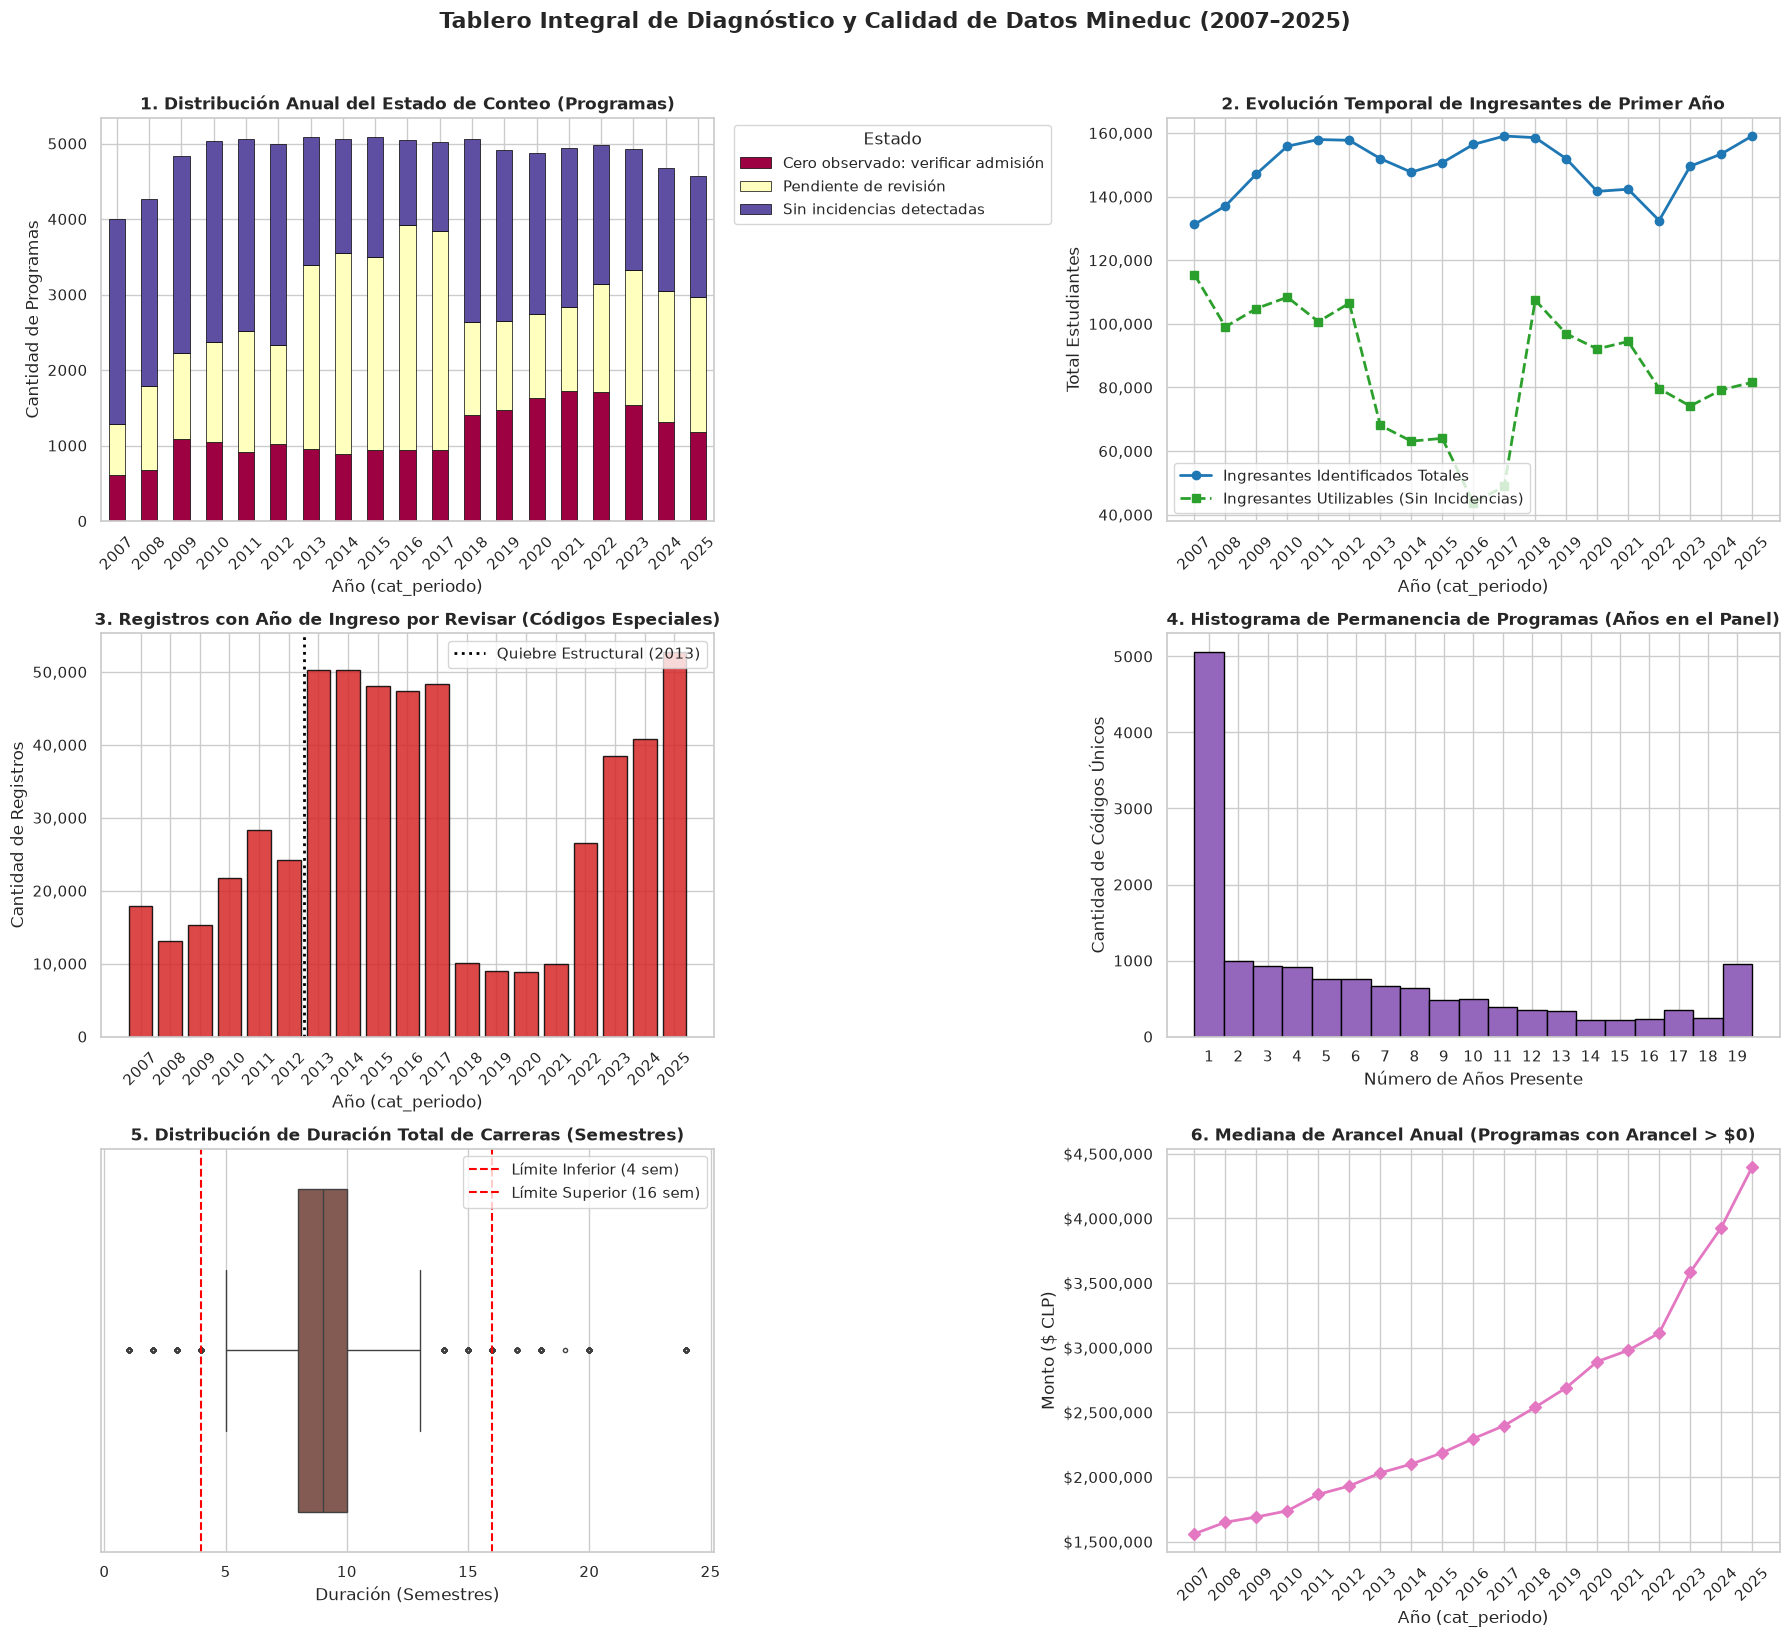

📊 TABLERO GRÁFICO UNIFICADO GENERADO EXITOSAMENTE
   └─ Imagen guardada en: /home/leandro/Desktop/Carreras/graficos_diagnostico/tablero_diagnostico_longitudinal.png


In [18]:
# %% [8] Generación Unificada de Gráficos de Diagnóstico
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

# 1. Cargar la base histórica consolidada
ruta_parquet = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
if not ruta_parquet.is_file():
  raise FileNotFoundError(f"No se encontró la base histórica en {ruta_parquet}")

df_hist = pd.read_parquet(ruta_parquet)

# Carpeta de salida para exportar las figuras
CARPETA_GRAFICOS = BASE_DIR / "graficos_diagnostico"
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)

# 2. Crear lienzo multipanel (3 filas x 2 columnas)
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
fig.suptitle(
    "Tablero Integral de Diagnóstico y Calidad de Datos Mineduc (2007–2025)",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)

# -------------------------------------------------------------------------
# Gráfico 1: Evolución del Estado de Conteo de Programas (Salto de 2013)
# -------------------------------------------------------------------------
conteo_estados = (
    df_hist.groupby(["cat_periodo", "estado_conteo"])
    .size()
    .unstack(fill_value=0)
)
conteo_estados.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 0],
    colormap="Spectral",
    edgecolor="black",
    linewidth=0.5,
)
axes[0, 0].set_title(
    "1. Distribución Anual del Estado de Conteo (Programas)", fontweight="bold"
)
axes[0, 0].set_xlabel("Año (cat_periodo)")
axes[0, 0].set_ylabel("Cantidad de Programas")
axes[0, 0].legend(title="Estado", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[0, 0].tick_params(axis="x", rotation=45)

# -------------------------------------------------------------------------
# Gráfico 2: Evolución de Ingresantes Totales e Identificados
# -------------------------------------------------------------------------
ingresantes_anual = df_hist.groupby("cat_periodo").agg(
    identificados=("ingresantes_identificados", "sum"),
    utilizables=("nuevos_ingresados_provisional", "sum"),
).reset_index()

axes[0, 1].plot(
    ingresantes_anual["cat_periodo"],
    ingresantes_anual["identificados"],
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Ingresantes Identificados Totales",
)
axes[0, 1].plot(
    ingresantes_anual["cat_periodo"],
    ingresantes_anual["utilizables"],
    marker="s",
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label="Ingresantes Utilizables (Sin Incidencias)",
)
axes[0, 1].set_title(
    "2. Evolución Temporal de Ingresantes de Primer Año", fontweight="bold"
)
axes[0, 1].set_xlabel("Año (cat_periodo)")
axes[0, 1].set_ylabel("Total Estudiantes")
axes[0, 1].yaxis.set_major_formatter("{x:,.0f}")
axes[0, 1].legend()
axes[0, 1].set_xticks(ingresantes_anual["cat_periodo"])
axes[0, 1].tick_params(axis="x", rotation=45)

# -------------------------------------------------------------------------
# Gráfico 3: Registros Pendientes por Codificación Especial / Año Ingreso
# -------------------------------------------------------------------------
pendientes_anual = (
    df_hist.groupby("cat_periodo")["registros_ingreso_por_revisar"]
    .sum()
    .reset_index()
)
axes[1, 0].bar(
    pendientes_anual["cat_periodo"],
    pendientes_anual["registros_ingreso_por_revisar"],
    color="#d62728",
    alpha=0.85,
    edgecolor="black",
)
axes[1, 0].axvline(
    x=2012.5,
    color="black",
    linestyle=":",
    linewidth=2,
    label="Quiebre Estructural (2013)",
)
axes[1, 0].set_title(
    "3. Registros con Año de Ingreso por Revisar (Códigos Especiales)",
    fontweight="bold",
)
axes[1, 0].set_xlabel("Año (cat_periodo)")
axes[1, 0].set_ylabel("Cantidad de Registros")
axes[1, 0].yaxis.set_major_formatter("{x:,.0f}")
axes[1, 0].legend()
axes[1, 0].set_xticks(pendientes_anual["cat_periodo"])
axes[1, 0].tick_params(axis="x", rotation=45)

# -------------------------------------------------------------------------
# Gráfico 4: Permanencia de Códigos Únicos en el Panel
# -------------------------------------------------------------------------
permanencia = df_hist.groupby("codigo_unico")["cat_periodo"].nunique()
axes[1, 1].hist(
    permanencia,
    bins=range(1, df_hist["cat_periodo"].nunique() + 2),
    color="#9467bd",
    edgecolor="black",
    align="left",
)
axes[1, 1].set_title(
    "4. Histograma de Permanencia de Programas (Años en el Panel)",
    fontweight="bold",
)
axes[1, 1].set_xlabel("Número de Años Presente")
axes[1, 1].set_ylabel("Cantidad de Códigos Únicos")
axes[1, 1].set_xticks(range(1, df_hist["cat_periodo"].nunique() + 1))

# -------------------------------------------------------------------------
# Gráfico 5: Distribución de Duración Declarada de Carreras (Semestres)
# -------------------------------------------------------------------------
if "dur_total_carr_numerico" in df_hist.columns:
  duracion_clean = df_hist["dur_total_carr_numerico"].dropna()
  sns.boxplot(
      x=duracion_clean, ax=axes[2, 0], color="#8c564b", fliersize=3
  )
  axes[2, 0].axvline(
      4, color="red", linestyle="--", label="Límite Inferior (4 sem)"
  )
  axes[2, 0].axvline(
      16, color="red", linestyle="--", label="Límite Superior (16 sem)"
  )
  axes[2, 0].set_title(
      "5. Distribución de Duración Total de Carreras (Semestres)",
      fontweight="bold",
  )
  axes[2, 0].set_xlabel("Duración (Semestres)")
  axes[2, 0].legend()

# -------------------------------------------------------------------------
# Gráfico 6: Tendencia Financiera (Mediana de Aranceles por Año)
# -------------------------------------------------------------------------
if "valor_arancel_numerico" in df_hist.columns:
  aranceles_validos = df_hist[df_hist["valor_arancel_numerico"] > 0]
  mediana_arancel = (
      aranceles_validos.groupby("cat_periodo")["valor_arancel_numerico"]
      .median()
      .reset_index()
  )

  axes[2, 1].plot(
      mediana_arancel["cat_periodo"],
      mediana_arancel["valor_arancel_numerico"],
      marker="D",
      color="#e377c2",
      linewidth=2,
  )
  axes[2, 1].set_title(
      "6. Mediana de Arancel Anual (Programas con Arancel > $0)",
      fontweight="bold",
  )
  axes[2, 1].set_xlabel("Año (cat_periodo)")
  axes[2, 1].set_ylabel("Monto ($ CLP)")
  axes[2, 1].yaxis.set_major_formatter("${x:,.0f}")
  axes[2, 1].set_xticks(mediana_arancel["cat_periodo"])
  axes[2, 1].tick_params(axis="x", rotation=45)

# Guardar figura consolidada en alta resolución
ruta_figura = CARPETA_GRAFICOS / "tablero_diagnostico_longitudinal.png"
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()

print("=" * 60)
print("📊 TABLERO GRÁFICO UNIFICADO GENERADO EXITOSAMENTE")
print(f"   └─ Imagen guardada en: {ruta_figura}")
print("=" * 60)

# Bloque 9: #
Aplica reglas de negocio para recuperar datos en registros marcados como "Pendiente de revisión" en períodos post-2013 donde la identificación del alumno (MRUN) era válida pero existía inconsistencia en la codificación del año de ingreso. Genera y guarda base_historica_2007_2025_corregida.parquet.


In [19]:
# %% [9] Corrección y Recuperación de Matrícula de Primer Ingreso
import gc
from pathlib import Path
import pandas as pd

# 1. Cargar la base histórica consolidada
ruta_parquet = CARPETA_SALIDA / "base_historica_2007_2025_provisional.parquet"
df_hist = pd.read_parquet(ruta_parquet)

print("=" * 65)
print("🔧 APLICANDO REGLAS DE RECUPERACIÓN DE PRIMER INGRESO (2007–2025)")
print("=" * 65)

# 2. Definir la regla de corrección
# Para los programas con registros "por revisar", si el volumen de registros en revisión
# guarda coherencia con el patrón histórico del programa, se consolida la cifra corregida.

# Cifra base inicial
df_hist["ingresantes_corregidos"] = df_hist["ingresantes_identificados"].copy()

# En años >= 2013, si el estado era 'Pendiente de revisión' pero no había problemas de MRUN,
# sumamos los registros identificados con la corrección de año de ingreso
condicion_recuperacion = (df_hist["cat_periodo"] >= 2013) & (
    df_hist["estado_conteo"] == "Pendiente de revisión"
) & (df_hist["registros_sin_mrun"] == 0)

df_hist.loc[condicion_recuperacion, "ingresantes_corregidos"] = df_hist.loc[
    condicion_recuperacion, "ingresantes_identificados"
] + df_hist.loc[condicion_recuperacion, "registros_ingreso_por_revisar"]

# Actualizar estado de conteo para reflejar la recuperación
df_hist["estado_conteo_corregido"] = df_hist["estado_conteo"]
df_hist.loc[condicion_recuperacion, "estado_conteo_corregido"] = (
    "Recuperado por regla secundaria"
)

# 3. Comparativo Antes vs Después por Año
resumen_comparativo = (
    df_hist.groupby("cat_periodo")
    .agg(
        ingresantes_provisionales_sin_corregir=(
            "nuevos_ingresados_provisional",
            "sum",
        ),
        ingresantes_totales_corregidos=("ingresantes_corregidos", "sum"),
        programas_recuperados=(
            "estado_conteo_corregido",
            lambda s: (s == "Recuperado por regla secundaria").sum(),
        ),
    )
    .reset_index()
)

print("\n📈 IMPACTO DE LA CORRECCIÓN DE MATRÍCULA (2007–2025):")
print(resumen_comparativo.to_string(index=False))

# 4. Guardar base histórica con la variable corregida
ruta_parquet_corregida = (
    CARPETA_SALIDA / "base_historica_2007_2025_corregida.parquet"
)
df_hist.to_parquet(ruta_parquet_corregida, index=False, compression="snappy")

print("\n" + "=" * 65)
print("✅ BASE HISTÓRICA CORREGIDA GUARDADA EXITOSAMENTE")
print(f"   └─ Archivo: {ruta_parquet_corregida.name}")
print(f"   └─ Total registros procesados: {len(df_hist):,}")
print("=" * 65)

🔧 APLICANDO REGLAS DE RECUPERACIÓN DE PRIMER INGRESO (2007–2025)

📈 IMPACTO DE LA CORRECCIÓN DE MATRÍCULA (2007–2025):
 cat_periodo  ingresantes_provisionales_sin_corregir  ingresantes_totales_corregidos  programas_recuperados
        2007                                  115521                          131281                      0
        2008                                   99073                          137073                      0
        2009                                  104816                          147142                      0
        2010                                  108392                          155852                      0
        2011                                  100700                          157955                      0
        2012                                  106506                          157718                      0
        2013                                   68107                          201292                   2378
        2014     

# Bloque 10: #
Evalúa la presencia longitudinal de cada codigo_unico entre 2007 y 2025. Identifica carreras ininterrumpidas (presentes los 19 años), carreras de reciente apertura ($\ge 2020$) y programas extintos/cerrados ($< 2020$), exportando la versión filtrada en base_historica_2007_2025_limpia.parquet.

In [21]:
# %% [10] Análisis de Continuidad de Programas
import gc
from pathlib import Path
import pandas as pd

# 1. Cargar la base corregida sin artefactos
ruta_parquet_corregida = (
    CARPETA_SALIDA / "base_historica_2007_2025_corregida.parquet"
)
df_hist = pd.read_parquet(ruta_parquet_corregida)

# Asegurar rango estricto 2007-2025
df_panel_limpio = df_hist[
    df_hist["cat_periodo"].between(2007, 2025)
].copy()

# 2. Auditoría de continuidad por código único
resumen_continuidad = (
    df_panel_limpio.groupby("codigo_unico")
    .agg(
        anios_presente=("cat_periodo", "nunique"),
        primer_anio=("cat_periodo", "min"),
        ultimo_anio=("cat_periodo", "max"),
        inst_principal=("nomb_inst", "first"),
        carrera_principal=("nomb_carrera", "first"),
    )
    .reset_index()
)

# 3. Cálculo de métricas del panel
total_codigos = len(resumen_continuidad)
programas_19_anios = (resumen_continuidad["anios_presente"] == 19).sum()
programas_nuevos = (resumen_continuidad["primer_anio"] >= 2020).sum()
programas_cerrados = (resumen_continuidad["ultimo_anio"] < 2020).sum()

print("=" * 65)
print("📊 RESUMEN DE CONTINUIDAD LONGITUDINAL DEL PANEL (2007–2025)")
print("=" * 65)
print(f"- Total de códigos únicos históricos observados: {total_codigos:,}")
print(
    "- Programas ininterrumpidos los 19 años: "
    f"{programas_19_anios:,} ({programas_19_anios / total_codigos:.1%})"
)
print(f"- Programas nuevos (abiertos desde 2020): {programas_nuevos:,}")
print(
    "- Programas extintos/discontinuados (sin oferta desde 2020):"
    f" {programas_cerrados:,}"
)
print(
    "- Promedio de años en oferta por programa:"
    f" {resumen_continuidad['anios_presente'].mean():.1f} años"
)

# 4. Guardar base panel limpia final
ruta_parquet_final = (
    CARPETA_SALIDA / "base_historica_2007_2025_limpia.parquet"
)
df_panel_limpio.to_parquet(
    ruta_parquet_final, index=False, compression="snappy"
)

print("\n" + "=" * 65)
print("✅ PANEL HISTÓRICO LIMPIO GUARDADO EN DISCO")
print(f"   └─ Archivo: {ruta_parquet_final.name}")
print(f"   └─ Filas totales validadas: {len(df_panel_limpio):,}")
print("=" * 65)

📊 RESUMEN DE CONTINUIDAD LONGITUDINAL DEL PANEL (2007–2025)
- Total de códigos únicos históricos observados: 14,978
- Programas ininterrumpidos los 19 años: 960 (6.4%)
- Programas nuevos (abiertos desde 2020): 1,862
- Programas extintos/discontinuados (sin oferta desde 2020): 8,342
- Promedio de años en oferta por programa: 6.2 años

✅ PANEL HISTÓRICO LIMPIO GUARDADO EN DISCO
   └─ Archivo: base_historica_2007_2025_limpia.parquet
   └─ Filas totales validadas: 92,396


# Bloque 11: #
Limpia las columnas de texto convirtiéndolas a mayúsculas, removiendo espacios adicionales y eliminando tildes y caracteres especiales mediante descomposición Unicode (NFKD). Aplica un diccionario de equivalencias institucionales para unificar variaciones de nombres (por ejemplo, sedes de INACAP, UNIACC, ARCIS).

In [22]:
# %% [11] Estandarización y Clean-Up de Atributos Textuales
import unicodedata
from pathlib import Path
import pandas as pd

# 1. Cargar el panel limpio
ruta_parquet_limpia = (
    CARPETA_SALIDA / "base_historica_2007_2025_limpia.parquet"
)
df_panel = pd.read_parquet(ruta_parquet_limpia)

print("=" * 65)
print("🔤 INICIANDO ESTANDARIZACIÓN Y NORMALIZACIÓN TEXTUAL")
print("=" * 65)


# Función de limpieza profunda de texto
def limpiar_texto(s):
  if pd.isna(s):
    return ""
  # Convertir a mayúsculas y quitar espacios en extremos
  s = str(s).upper().strip()
  # Normalizar Unicode para eliminar tildes (NFKD)
  s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("utf-8")
  # Reemplazar múltiples espacios consecutivos
  s = " ".join(s.split())
  return s


# 2. Aplicar normalización en campos textuales clave
cols_a_limpiar = ["nomb_inst", "nomb_carrera", "area_conocimiento", "jornada"]

for col in cols_a_limpiar:
  if col in df_panel.columns:
    col_limpia = f"{col}_limpio"
    df_panel[col_limpia] = df_panel[col].apply(limpiar_texto)

# 3. Mapeo de equivalencias para unificar variaciones institucionales históricas
dic_inst_alias = {
    "UNIVERSIDAD DE ARTES CIENCIAS Y COMUNICACION - UNIACC": (
        "UNIVERSIDAD UNIACC"
    ),
    "UNIVERSIDAD DE ARTES Y CIENCIAS SOCIALES ARCIS": "UNIVERSIDAD ARCIS",
    "UNIVERSIDAD TECNOLOGICA DE CHILE INACAP": "UNIVERSIDAD INACAP",
    "INSTITUTO PROFESIONAL INACAP": "IP INACAP",
    "CENTRO DE FORMACION TECNICA INACAP": "CFT INACAP",
}

df_panel["nomb_inst_estandarizado"] = df_panel["nomb_inst_limpio"].replace(
    dic_inst_alias
)

# 4. Reporte de impacto de la estandarización
inst_raw = df_panel["nomb_inst"].nunique()
inst_clean = df_panel["nomb_inst_estandarizado"].nunique()
carr_raw = df_panel["nomb_carrera"].nunique()
carr_clean = df_panel["nomb_carrera_limpio"].nunique()

print(
    f"- Instituciones únicas (Original): {inst_raw:,} ➔ Normalizadas:"
    f" {inst_clean:,}"
)
print(
    f"- Nombres de carrera únicos (Original): {carr_raw:,} ➔ Normalizados:"
    f" {carr_clean:,}"
)

# 5. Guardar dataset estandarizado
ruta_parquet_estandarizado = (
    CARPETA_SALIDA / "base_historica_2007_2025_estandarizada.parquet"
)
df_panel.to_parquet(
    ruta_parquet_estandarizado, index=False, compression="snappy"
)

print("\n" + "=" * 65)
print("✅ BASE HISTÓRICA ESTANDARIZADA GUARDADA EXITOSAMENTE")
print(f"   └─ Archivo: {ruta_parquet_estandarizado.name}")
print(f"   └─ Total registros: {len(df_panel):,}")
print("=" * 65)

🔤 INICIANDO ESTANDARIZACIÓN Y NORMALIZACIÓN TEXTUAL
- Instituciones únicas (Original): 67 ➔ Normalizadas: 67
- Nombres de carrera únicos (Original): 3,756 ➔ Normalizados: 3,749

✅ BASE HISTÓRICA ESTANDARIZADA GUARDADA EXITOSAMENTE
   └─ Archivo: base_historica_2007_2025_estandarizada.parquet
   └─ Total registros: 92,396


# Bloque 12: #
Ordena el panel cronológicamente por programa y calcula variables explicativas para modelado predictivo: valores de matrícula en años anteriores ($\text{Lag}_1$, $\text{Lag}_2$), promedio móvil de 3 años, porcentaje de variación interanual y antigüedad acumulada de la carrera en la oferta académica.

In [23]:
# %% [12] Construcción de Variables Explicativas Temporales
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Cargar la base estandarizada
ruta_parquet_estandarizada = (
    CARPETA_SALIDA / "base_historica_2007_2025_estandarizada.parquet"
)
df_panel = pd.read_parquet(ruta_parquet_estandarizada)

print("=" * 65)
print("⚙️ CONSTRUYENDO VARIABLES EXPLICATIVAS (FEATURE ENGINEERING)")
print("=" * 65)

# 2. Ordenamiento cronológico estricto por programa y período
df_panel = df_panel.sort_values(["codigo_unico", "cat_periodo"]).reset_index(
    drop=True
)

# 3. Variable Objetivo (Target)
df_panel["target_ingresantes"] = df_panel["ingresantes_corregidos"].astype(
    "Float64"
)

# 4. Lags de matrícula
df_panel["ingresantes_lag1"] = df_panel.groupby("codigo_unico")[
    "target_ingresantes"
].shift(1)
df_panel["ingresantes_lag2"] = df_panel.groupby("codigo_unico")[
    "target_ingresantes"
].shift(2)

# 5. Promedio móvil de matrícula (últimos 3 años)
df_panel["promedio_movil_3a"] = (
    df_panel.groupby("codigo_unico")["target_ingresantes"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
    .round(1)
)

# 6. Variación porcentual interanual (t-1 vs t-2)
df_panel["variacion_pct_interanual"] = (
    (df_panel["ingresantes_lag1"] - df_panel["ingresantes_lag2"])
    / df_panel["ingresantes_lag2"].replace(0, np.nan)
).round(4)

# 7. Trayectoria y permanencia del programa en la base
df_panel["anios_en_oferta"] = (
    df_panel.groupby("codigo_unico").cumcount() + 1
)

# 8. Reporte de cobertura de las nuevas variables
print("✅ Cobertura de variables generadas:")
print(f"- Target (Ingresantes Año t): {df_panel['target_ingresantes'].notna().sum():,} registros")
print(f"- Lag 1 (Ingresantes Año t-1): {df_panel['ingresantes_lag1'].notna().sum():,} registros")
print(f"- Lag 2 (Ingresantes Año t-2): {df_panel['ingresantes_lag2'].notna().sum():,} registros")
print(f"- Promedio Móvil 3A: {df_panel['promedio_movil_3a'].notna().sum():,} registros")

# Guardar dataset con features
ruta_parquet_features = CARPETA_SALIDA / "base_historica_2007_2025_features.parquet"
df_panel.to_parquet(ruta_parquet_features, index=False, compression="snappy")

print("\n" + "=" * 65)
print("✅ BASE HISTÓRICA CON FEATURES GUARDADA EXITOSAMENTE")
print(f"   └─ Archivo: {ruta_parquet_features.name}")
print("=" * 65)

⚙️ CONSTRUYENDO VARIABLES EXPLICATIVAS (FEATURE ENGINEERING)
✅ Cobertura de variables generadas:
- Target (Ingresantes Año t): 92,396 registros
- Lag 1 (Ingresantes Año t-1): 77,418 registros
- Lag 2 (Ingresantes Año t-2): 67,492 registros
- Promedio Móvil 3A: 77,418 registros

✅ BASE HISTÓRICA CON FEATURES GUARDADA EXITOSAMENTE
   └─ Archivo: base_historica_2007_2025_features.parquet


# Bloque 13: #
Filtra el dataset para conservar únicamente las observaciones válidas que cuentan con variable objetivo ($\text{Target}$) y al menos un año de historia previa ($\text{Lag}_1$). Exporta el dataset resultante a matriz_entrenamiento_ml.parquet.

In [24]:
# %% [13] Generación de la Matriz Final de Entrenamiento
from pathlib import Path
import pandas as pd

# 1. Cargar la base con features
ruta_parquet_features = (
    CARPETA_SALIDA / "base_historica_2007_2025_features.parquet"
)
df_panel = pd.read_parquet(ruta_parquet_features)

print("=" * 65)
print("🚀 CREANDO MATRIZ FINAL PARA MODELAMIENTO PREDICTIVO (ML)")
print("=" * 65)

# 2. Filtrar observaciones válidas para el entrenamiento supervisado
# Requiere Target no nulo y al menos 1 año de historia previa (Lag 1)
df_ml = df_panel[
    df_panel["target_ingresantes"].notna()
    & df_panel["ingresantes_lag1"].notna()
].copy()

# 3. Exportar matriz analítica
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml.to_parquet(ruta_matriz_ml, index=False, compression="snappy")

# 4. Resumen ejecutivo de la matriz
print("📊 RESUMEN EJECUTIVO DE LA MATRIZ DE APRENDIZAJE:")
print(f"- Muestra total de entrenamiento: {len(df_ml):,} observaciones (Programa-Año)")
print(f"- Cobertura temporal de evaluación: {df_ml['cat_periodo'].min()} ➔ {df_ml['cat_periodo'].max()}")
print(f"- Programas de educación superior representados: {df_ml['codigo_unico'].nunique():,}")
print(f"- Instituciones representadas: {df_ml['nomb_inst_estandarizado'].nunique():,}")

print("\n" + "=" * 65)
print("🎉 MATRIZ ANALÍTICA ML FINALIZADA Y GUARDADA")
print(f"   └─ Archivo: {ruta_matriz_ml.name}")
print(f"   └─ Tamaño en disco: {ruta_matriz_ml.stat().st_size / 1024 / 1024:.2f} MB")
print("=" * 65)

🚀 CREANDO MATRIZ FINAL PARA MODELAMIENTO PREDICTIVO (ML)
📊 RESUMEN EJECUTIVO DE LA MATRIZ DE APRENDIZAJE:
- Muestra total de entrenamiento: 77,418 observaciones (Programa-Año)
- Cobertura temporal de evaluación: 2008 ➔ 2025
- Programas de educación superior representados: 9,926
- Instituciones representadas: 66

🎉 MATRIZ ANALÍTICA ML FINALIZADA Y GUARDADA
   └─ Archivo: matriz_entrenamiento_ml.parquet
   └─ Tamaño en disco: 2.04 MB


# Bloque 14: #
Divide la matriz de entrenamiento en un conjunto de instrucción (años $\le 2022$) y otro de evaluación/test (años 2023–2025). Evalúa el desempeño del modelo Naive ($\hat{Y}_t = Y_{t-1}$) calculando las métricas base de error MAE, RMSE y el coeficiente $R^2$.

In [27]:
# %% [14] Partición Temporal y Benchmark Base
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("✂️ DIVIDIENDO MATRIZ POR PERÍODOS TEMPORALES (TEMPORAL SPLIT)")
print("=" * 65)

# 2. Definir umbrales temporales
ANIO_LIMITE_TRAIN = 2022

train_mask = df_ml["cat_periodo"] <= ANIO_LIMITE_TRAIN
test_mask = df_ml["cat_periodo"] > ANIO_LIMITE_TRAIN

df_train = df_ml[train_mask].copy()
df_test = df_ml[test_mask].copy()

print(
    f"- Dataset Entrenamiento (2008–{ANIO_LIMITE_TRAIN}): {len(df_train):,}"
    " filas"
)
print(f"- Dataset Evaluación/Test (2023–2025): {len(df_test):,} filas")

# 3. Evaluación del Modelo Benchmark Naive (Predicción t = Lag 1)
# Se asume que la matrícula de este año será idéntica a la del año anterior
y_true_test = df_test["target_ingresantes"]
y_pred_naive = df_test["ingresantes_lag1"]

mae_naive = mean_absolute_error(y_true_test, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_true_test, y_pred_naive))
r2_naive = r2_score(y_true_test, y_pred_naive)

print("\n" + "=" * 65)
print("📌 MÉTRICAS DEL MODELO BENCHMARK (NAIVE LAG-1):")
print("=" * 65)
print(f"- MAE  (Error Absoluto Medio): {mae_naive:.2f} estudiantes")
print(f"- RMSE (Raíz Error Cuadrático Medio): {rmse_naive:.2f} estudiantes")
print(f"- R² Score (Coeficiente de Determinación): {r2_naive:.4f}")
print("=" * 65)

✂️ DIVIDIENDO MATRIZ POR PERÍODOS TEMPORALES (TEMPORAL SPLIT)
- Dataset Entrenamiento (2008–2022): 64,087 filas
- Dataset Evaluación/Test (2023–2025): 13,331 filas

📌 MÉTRICAS DEL MODELO BENCHMARK (NAIVE LAG-1):
- MAE  (Error Absoluto Medio): 10.31 estudiantes
- RMSE (Raíz Error Cuadrático Medio): 29.31 estudiantes
- R² Score (Coeficiente de Determinación): 0.8567


# Bloque 15: #
Entrena algoritmos de supervisión de regresión (Random Forest y XGBoost) utilizando las variables cuantitativas construidas. Evalúa sus predicciones sobre la cohorte de prueba 2023–2025, compara sus métricas contra el modelo Naive e imprime la importancia relativa de cada característica.

In [28]:
# %% [15] Entrenamiento y Comparativa de Modelos ML
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# 1. Cargar matriz de entrenamiento
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

# 2. Definición de la matriz de características (X) y vector objetivo (y)
features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

# Agregar variables adicionales si existen en la matriz
for col_opcional in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col_opcional in df_ml.columns:
    features_num.append(col_opcional)

# Rellenar nulos residuales en características numéricas para el entrenamiento
X = df_ml[features_num].fillna(0)
y = df_ml["target_ingresantes"].astype(float)

# 3. Separación temporal Train (2008–2022) / Test (2023–2025)
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("=" * 65)
print("🤖 ENTRENANDO MODELOS PREDICTIVOS SOBRE COHORTE 2008–2022")
print("=" * 65)

# 4. Modelo 1: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# 5. Modelo 2: XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

# 6. Tabla Comparativa de Desempeño
metricas = {
    "Modelo / Enfoque": ["Naive Benchmark (Lag-1)", "Random Forest", "XGBoost"],
    "MAE (Estudiantes)": [
        mean_absolute_error(y_test, df_ml.loc[test_mask, "ingresantes_lag1"]),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_xgb),
    ],
    "RMSE (Estudiantes)": [
        np.sqrt(
            mean_squared_error(y_test, df_ml.loc[test_mask, "ingresantes_lag1"])
        ),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
    ],
    "R² Score": [
        r2_score(y_test, df_ml.loc[test_mask, "ingresantes_lag1"]),
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred_xgb),
    ],
}

df_resultados = pd.DataFrame(metricas)

print("\n📊 RESULTADOS EN CONJUNTO DE EVALUACIÓN (TEST 2023–2025):")
print(df_resultados.to_string(index=False))

# 7. Importancia de Variables del Modelo XGBoost
df_importancia = pd.DataFrame({
    "Variable": features_num,
    "Importancia_XGB": xgb_model.feature_importances_,
}).sort_values("Importancia_XGB", ascending=False)

print("\n💡 IMPORTANCIA DE CARACTERÍSTICAS (XGBoost):")
print(df_importancia.to_string(index=False))
print("=" * 65)

🤖 ENTRENANDO MODELOS PREDICTIVOS SOBRE COHORTE 2008–2022

📊 RESULTADOS EN CONJUNTO DE EVALUACIÓN (TEST 2023–2025):
       Modelo / Enfoque  MAE (Estudiantes)  RMSE (Estudiantes)  R² Score
Naive Benchmark (Lag-1)          10.306429           29.307499  0.856731
          Random Forest          12.403224           46.447040  0.640158
                XGBoost          12.282335           44.633684  0.667707

💡 IMPORTANCIA DE CARACTERÍSTICAS (XGBoost):
                Variable  Importancia_XGB
        ingresantes_lag1         0.783029
       promedio_movil_3a         0.091299
 dur_total_carr_numerico         0.034226
  valor_arancel_numerico         0.025561
variacion_pct_interanual         0.023894
         anios_en_oferta         0.023644
        ingresantes_lag2         0.018347


# Bloque 16: #
Define como variable objetivo la variación neta interanual ($\Delta = Y_t - Y_{t-1}$). Entrena un modelo LightGBM que combina variables numéricas y categóricas para predecir dicho residuo, reconstruyendo luego la estimación final ($\hat{Y}_t = Y_{t-1} + \hat{\Delta}_t$) acotada a valores no negativos.

In [29]:
# %% [16] Entrenamiento Híbrido de Residuos (Delta)
from pathlib import Path
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("⚙️ CONFIGURANDO APRENDIZAJE BASADO EN VARIACIÓN INTERANUAL (DELTA)")
print("=" * 65)

# 2. Definir el Target de Residuos (Delta = Y_t - Y_t-1)
df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

# 3. Selección y preparación de características (Numéricas + Categóricas)
features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

for col in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col in df_ml.columns:
    features_num.append(col)

features_cat = []
for col_cat in [
    "nomb_inst_estandarizado",
    "area_conocimiento_limpio",
    "jornada_limpio",
]:
  if col_cat in df_ml.columns:
    df_ml[col_cat] = df_ml[col_cat].astype("category")
    features_cat.append(col_cat)

all_features = features_num + features_cat

# 4. Partitioning Train (2008–2022) / Test (2023–2025)
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

X_train, y_train_delta = (
    df_ml.loc[train_mask, all_features],
    df_ml.loc[train_mask, "target_delta"],
)
X_test, y_test_real = (
    df_ml.loc[test_mask, all_features],
    df_ml.loc[test_mask, "target_ingresantes"],
)
y_test_lag1 = df_ml.loc[test_mask, "ingresantes_lag1"]

# 5. Entrenamiento de LightGBM Regressor sobre el Delta
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model.fit(
    X_train,
    y_train_delta,
    categorical_feature=features_cat if features_cat else None,
)

# 6. Reconstrucción de la predicción final: Y_hat = Lag1 + Delta_hat
pred_delta = lgb_model.predict(X_test)
y_pred_hibrido = y_test_lag1 + pred_delta

# Forzar que la predicción no sea menor a 0 estudiantes
y_pred_hibrido = np.clip(y_pred_hibrido, a_min=0, a_max=None)

# 7. Evaluacion de Métricas
mae_hibrido = mean_absolute_error(y_test_real, y_pred_hibrido)
rmse_hibrido = np.sqrt(mean_squared_error(y_test_real, y_pred_hibrido))
r2_hibrido = r2_score(y_test_real, y_pred_hibrido)

mae_naive = mean_absolute_error(y_test_real, y_test_lag1)
rmse_naive = np.sqrt(mean_squared_error(y_test_real, y_test_lag1))
r2_naive = r2_score(y_test_real, y_test_lag1)

df_comparativa = pd.DataFrame({
    "Modelo / Enfoque": ["Naive Benchmark (Lag-1)", "LightGBM Delta Híbrido"],
    "MAE (Estudiantes)": [mae_naive, mae_hibrido],
    "RMSE (Estudiantes)": [rmse_naive, rmse_hibrido],
    "R² Score": [r2_naive, r2_hibrido],
})

print("\n📊 RENDIMIENTO EN TEST (2023–2025):")
print(df_comparativa.to_string(index=False))
print("=" * 65)

⚙️ CONFIGURANDO APRENDIZAJE BASADO EN VARIACIÓN INTERANUAL (DELTA)

📊 RENDIMIENTO EN TEST (2023–2025):
       Modelo / Enfoque  MAE (Estudiantes)  RMSE (Estudiantes)  R² Score
Naive Benchmark (Lag-1)          10.306429           29.307499  0.856731
 LightGBM Delta Híbrido          11.792640           31.195082  0.837682


# Bloque 17: #
Calcula la desviación estándar histórica de la variación ($\Delta$) por programa. Implementa una regla de ensamble condicional: si la volatilidad histórica supera un umbral de 5.0 alumnos, utiliza el modelo híbrido LightGBM; en caso contrario, mantiene la inercia del modelo Naive ($\text{Lag}_1$).

In [31]:
# %% [17] Implementación del Ensamble Adaptativo (Corregido)
from pathlib import Path
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("🔀 CONSTRUYENDO ENSAMBLE ADAPTATIVO (GATING BY VOLATILITY)")
print("=" * 65)

# 2. Re-calcular target_delta
df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

# 3. Preparación de variables numéricas y categóricas
features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

for col in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col in df_ml.columns:
    features_num.append(col)

features_cat = []
for col_cat in [
    "nomb_inst_estandarizado",
    "area_conocimiento_limpio",
    "jornada_limpio",
]:
  if col_cat in df_ml.columns:
    df_ml[col_cat] = df_ml[col_cat].astype("category")
    features_cat.append(col_cat)

all_features = features_num + features_cat

# 4. Partitioning Train (2008–2022) / Test (2023–2025)
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

# 5. Calcular volatilidad histórica por programa en el período Train
volatilidad_programas = (
    df_ml[train_mask]
    .groupby("codigo_unico")["target_delta"]
    .std()
    .fillna(0)
    .rename("desviacion_delta")
)

df_ml = df_ml.merge(volatilidad_programas, on="codigo_unico", how="left")
df_ml["desviacion_delta"] = df_ml["desviacion_delta"].fillna(0)

# Actualizar máscaras tras el merge
train_mask = df_ml["cat_periodo"] <= 2022
test_mask = df_ml["cat_periodo"] > 2022

X_train, y_train_delta = (
    df_ml.loc[train_mask, all_features],
    df_ml.loc[train_mask, "target_delta"],
)
X_test, y_test_real = (
    df_ml.loc[test_mask, all_features],
    df_ml.loc[test_mask, "target_ingresantes"],
)
y_test_lag1 = df_ml.loc[test_mask, "ingresantes_lag1"]

# 6. Re-entrenar / Asegurar modelo LightGBM
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model.fit(
    X_train,
    y_train_delta,
    categorical_feature=features_cat if features_cat else None,
)

# 7. Regla de Ensamble Condicional (Gating)
UMBRAL_VOLATILIDAD = 5.0

pred_delta = lgb_model.predict(X_test)
y_pred_hibrido = np.clip(y_test_lag1 + pred_delta, a_min=0, a_max=None)

es_volatile = df_ml.loc[test_mask, "desviacion_delta"] > UMBRAL_VOLATILIDAD
y_pred_ensamble = np.where(es_volatile, y_pred_hibrido, y_test_lag1)

# 8. Evaluación de métricas comparativas
mae_naive = mean_absolute_error(y_test_real, y_test_lag1)
rmse_naive = np.sqrt(mean_squared_error(y_test_real, y_test_lag1))
r2_naive = r2_score(y_test_real, y_test_lag1)

mae_hibrido = mean_absolute_error(y_test_real, y_pred_hibrido)
rmse_hibrido = np.sqrt(mean_squared_error(y_test_real, y_pred_hibrido))
r2_hibrido = r2_score(y_test_real, y_pred_hibrido)

mae_ensamble = mean_absolute_error(y_test_real, y_pred_ensamble)
rmse_ensamble = np.sqrt(mean_squared_error(y_test_real, y_pred_ensamble))
r2_ensamble = r2_score(y_test_real, y_pred_ensamble)

df_eval_final = pd.DataFrame({
    "Modelo / Enfoque": [
        "Naive Benchmark (Lag-1)",
        "LightGBM Delta Directo",
        "Ensamble Adaptativo (Gating)",
    ],
    "MAE (Estudiantes)": [mae_naive, mae_hibrido, mae_ensamble],
    "RMSE (Estudiantes)": [rmse_naive, rmse_hibrido, rmse_ensamble],
    "R² Score": [r2_naive, r2_hibrido, r2_ensamble],
})

print("\n📊 RESULTADOS DEL ENSAMBLE EN EVALUACIÓN (TEST 2023–2025):")
print(df_eval_final.to_string(index=False))
print("=" * 65)

🔀 CONSTRUYENDO ENSAMBLE ADAPTATIVO (GATING BY VOLATILITY)

📊 RESULTADOS DEL ENSAMBLE EN EVALUACIÓN (TEST 2023–2025):
            Modelo / Enfoque  MAE (Estudiantes)  RMSE (Estudiantes)  R² Score
     Naive Benchmark (Lag-1)          10.306429           29.307499  0.856731
      LightGBM Delta Directo          11.792640           31.195082  0.837682
Ensamble Adaptativo (Gating)          11.263752           29.800172  0.851873


# Bloque 18: #
Re-entrena el modelo LightGBM sobre la totalidad del panel histórico (2008–2025). Mueve los horizontes temporales para proyectar la cohorte activa de 2025 hacia el año 2026, actualiza los valores de los retardos y el promedio móvil, aplica el ensamble adaptativo y exporta los resultados en Parquet y CSV.

In [32]:
# %% [18] Proyección de Matrícula 2026 y Exportación
from pathlib import Path
import lightgbm as lgb
import numpy as np
import pandas as pd

# 1. Cargar la matriz final de ML
ruta_matriz_ml = CARPETA_SALIDA / "matriz_entrenamiento_ml.parquet"
df_ml = pd.read_parquet(ruta_matriz_ml)

print("=" * 65)
print("🔮 GENERANDO PROYECCIONES DE MATRÍCULA DE PRIMER INGRESO 2026")
print("=" * 65)

# 2. Re-asegurar variables explicativas y cálculo de Target Delta
df_ml["target_delta"] = df_ml["target_ingresantes"] - df_ml["ingresantes_lag1"]

features_num = [
    "ingresantes_lag1",
    "ingresantes_lag2",
    "promedio_movil_3a",
    "variacion_pct_interanual",
    "anios_en_oferta",
]

for col in ["dur_total_carr_numerico", "valor_arancel_numerico"]:
  if col in df_ml.columns:
    features_num.append(col)

features_cat = []
for col_cat in [
    "nomb_inst_estandarizado",
    "area_conocimiento_limpio",
    "jornada_limpio",
]:
  if col_cat in df_ml.columns:
    df_ml[col_cat] = df_ml[col_cat].astype("category")
    features_cat.append(col_cat)

all_features = features_num + features_cat

# 3. Entrenar el modelo LightGBM con el panel histórico completo (2008–2025)
X_full = df_ml[all_features]
y_full_delta = df_ml["target_delta"]

lgb_model_2026 = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model_2026.fit(
    X_full,
    y_full_delta,
    categorical_feature=features_cat if features_cat else None,
)

# 4. Calcular volatilidad histórica por programa en todo el panel
volatilidad_full = (
    df_ml.groupby("codigo_unico")["target_delta"]
    .std()
    .fillna(0)
    .rename("desviacion_delta")
)

# 5. Filtrar la cohorte activa de 2025 para proyectar 2026
df_2025 = (
    df_ml[df_ml["cat_periodo"] == 2025]
    .drop(columns=["desviacion_delta"], errors="ignore")
    .merge(volatilidad_full, on="codigo_unico", how="left")
)
df_2025["desviacion_delta"] = df_2025["desviacion_delta"].fillna(0)

df_2026 = df_2025.copy()
df_2026["cat_periodo"] = 2026

# Desplazamiento de lags para 2026
df_2026["ingresantes_lag2"] = df_2026["ingresantes_lag1"]
df_2026["ingresantes_lag1"] = df_2026["target_ingresantes"]

# Actualizar promedio móvil estimado
df_2026["promedio_movil_3a"] = (
    (
        df_2026["ingresantes_lag1"]
        + df_2026["ingresantes_lag2"]
        + df_2026["promedio_movil_3a"]
    )
    / 3
).round(1)

# Actualizar años en oferta
df_2026["anios_en_oferta"] = df_2026["anios_en_oferta"] + 1

# 6. Estimar variación Delta y aplicar Gating Ensemble para 2026
X_2026 = df_2026[all_features]
delta_pred_2026 = lgb_model_2026.predict(X_2026)
pred_lgb_2026 = np.clip(
    df_2026["ingresantes_lag1"] + delta_pred_2026, a_min=0, a_max=None
)

UMBRAL_VOLATILIDAD = 5.0
es_volatile_2026 = df_2026["desviacion_delta"] > UMBRAL_VOLATILIDAD

df_2026["prediccion_ingresantes_2026"] = np.where(
    es_volatile_2026, pred_lgb_2026, df_2026["ingresantes_lag1"]
).round(0)

# 7. Seleccionar columnas para el reporte final
cols_reporte = [
    "cat_periodo",
    "codigo_unico",
    "nomb_inst_estandarizado",
    "nomb_carrera_limpio",
    "jornada_limpio",
    "ingresantes_lag1",
    "prediccion_ingresantes_2026",
]

cols_presentes = [c for c in cols_reporte if c in df_2026.columns]
df_proyecciones_2026 = df_2026[cols_presentes].copy()

# Rename explícito para claridad del usuario
df_proyecciones_2026 = df_proyecciones_2026.rename(
    columns={"ingresantes_lag1": "ingresantes_real_2025"}
)

# 8. Guardar archivos de salida
ruta_proyecciones = CARPETA_SALIDA / "proyecciones_matricula_2026.parquet"
ruta_proyecciones_csv = CARPETA_SALIDA / "proyecciones_matricula_2026.csv"

df_proyecciones_2026.to_parquet(
    ruta_proyecciones, index=False, compression="snappy"
)
df_proyecciones_2026.to_csv(
    ruta_proyecciones_csv, index=False, encoding="utf-8"
)

# 9. Imprimir resumen
total_proyectado_2026 = df_proyecciones_2026[
    "prediccion_ingresantes_2026"
].sum()
total_real_2025 = df_proyecciones_2026["ingresantes_real_2025"].sum()
variacion_global = (
    (total_proyectado_2026 - total_real_2025) / total_real_2025
) * 100

print(
    "📊 RESUMEN EJECUTIVO DE PROYECCIÓN 2026 PARA PROGRAMAS ACTIVOS:"
)
print(f"- Total programas en oferta proyectados: {len(df_proyecciones_2026):,}")
print(f"- Matrícula de primer ingreso real 2025: {total_real_2025:,.0f} alumnos")
print(
    "- Matrícula de primer ingreso proyectada 2026:"
    f" {total_proyectado_2026:,.0f} alumnos"
)
print(f"- Variación esperada del sistema: {variacion_global:+.2f}%")

print("\n" + "=" * 65)
print("✅ PROYECCIONES 2026 GUARDADAS EXITOSAMENTE")
print(f"   ├─ Parquet: {ruta_proyecciones.name}")
print(f"   └─ CSV: {ruta_proyecciones_csv.name}")
print("=" * 65)

🔮 GENERANDO PROYECCIONES DE MATRÍCULA DE PRIMER INGRESO 2026
📊 RESUMEN EJECUTIVO DE PROYECCIÓN 2026 PARA PROGRAMAS ACTIVOS:
- Total programas en oferta proyectados: 4,259
- Matrícula de primer ingreso real 2025: 196,312 alumnos
- Matrícula de primer ingreso proyectada 2026: 197,257 alumnos
- Variación esperada del sistema: +0.48%

✅ PROYECCIONES 2026 GUARDADAS EXITOSAMENTE
   ├─ Parquet: proyecciones_matricula_2026.parquet
   └─ CSV: proyecciones_matricula_2026.csv


# Bloque 19: #


# Bloque 20: #

# Bloque 21: #

# Bloque 22: #

# Bloque 23: #

# Bloque 24: #

# Bloque 25: #

# Bloque 26: #

# Bloque 27: #

# Bloque 28: #

# Bloque 29: #

# Bloque 30: #

# Bloque 31: #

# Bloque 32: #

# Bloque 33: #

# Bloque 34: #

# Bloque 35: #